# 06 · Does the chain transfer to Facebook and Instagram?

Views are unknown on Facebook and Instagram, so an estimate there is a chain of two links:
1. **followers + text -> likes, comments, shares** (observed on all five platforms, so this link can be checked everywhere)
2. **likes, comments -> views** (can be checked only on TikTok, YouTube and X)

Question: how much of each link survives a move to another platform? Brand-grouped CV on the diagonal; off-diagonal = train on one whole platform, test on another.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, xplat as xp, transfer as tf

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200, "display.max_columns", 30)

In [2]:
X, Y, meta = xp.load(ROOT)
Y.notna().groupby(meta.platform).mean().reindex(xp.ALL).rename(index=eu.NAMES).round(2)

,likes,comments,shares
platform,,,
TikTok,1.00,1.00,1.00
YouTube,0.95,0.91,0.59
X (Twitter),1.00,0.31,1.00
Facebook,1.00,1.00,1.00
Instagram,1.00,1.00,0.00


## Link 1 · predicting likes, comments, shares
Features that exist everywhere: followers (and a missing flag), simple text statistics, VADER sentiment, English flag, hour, weekday. Left panel: rank correlation; right: skill against the median of the test platform (negative = worse than a constant).

In [3]:
res = {t: xp.matrix(X, Y, meta, t) for t in ["likes", "comments", "shares"]}
res["likes"][1].round(2).rename(index=eu.NAMES, columns=eu.NAMES)

,TikTok,YouTube,X (Twitter),Facebook,Instagram
TikTok,0.44,0.31,0.23,0.33,0.26
YouTube,0.26,0.47,0.17,0.29,0.14
X (Twitter),0.29,0.19,0.33,0.16,0.00
Facebook,0.37,0.33,0.09,0.41,-0.11
Instagram,0.40,0.35,0.24,0.33,0.29


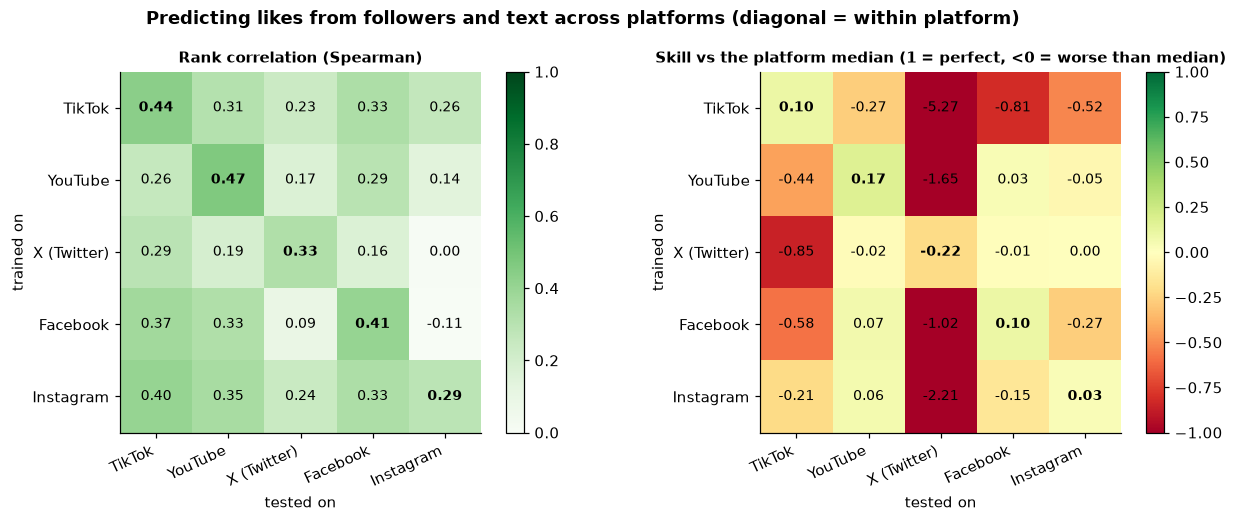

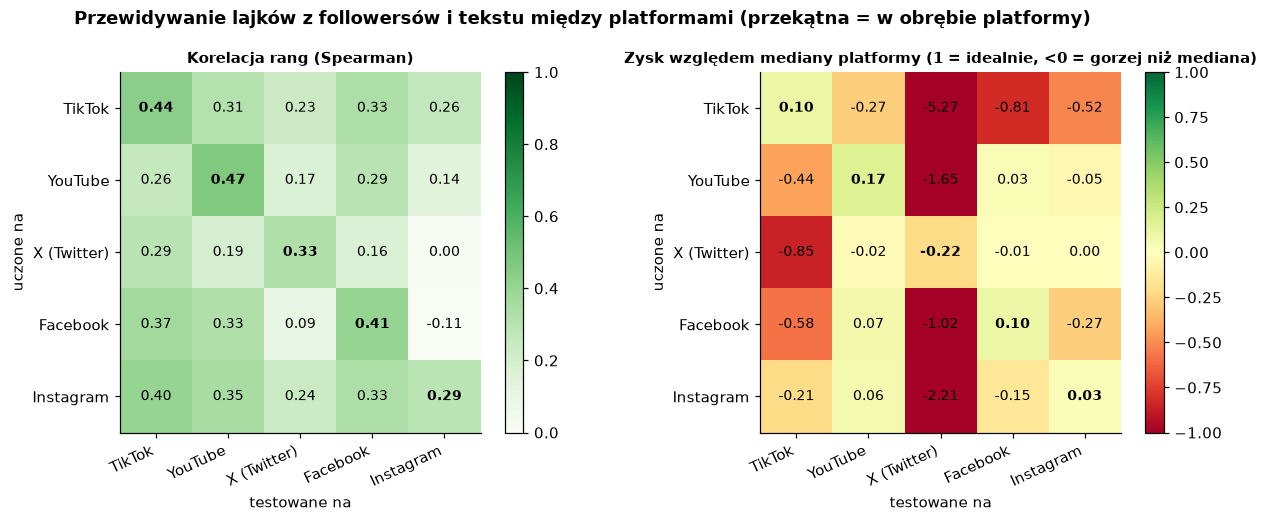

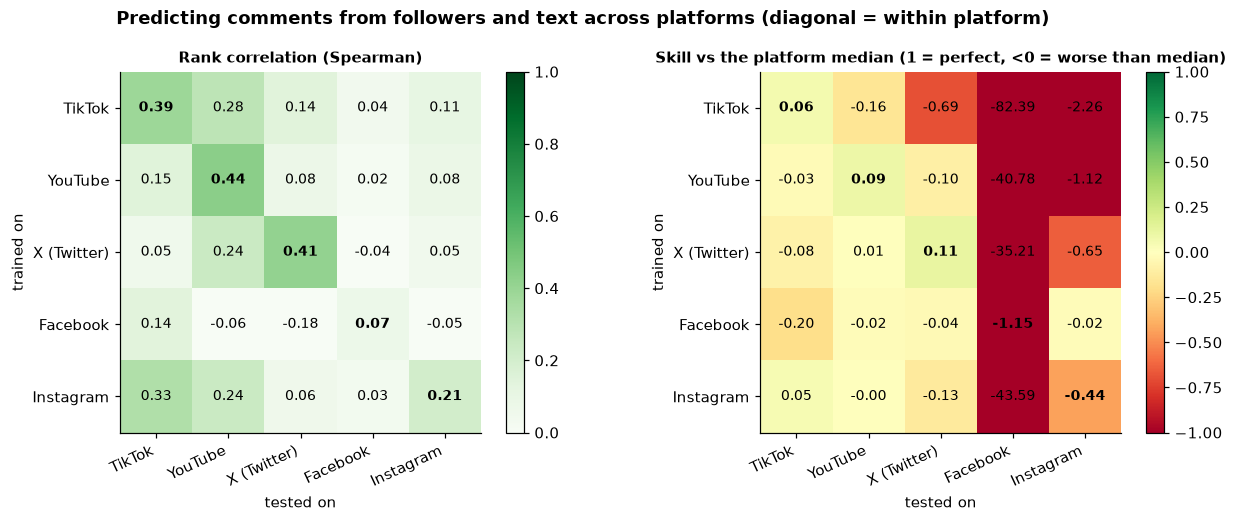

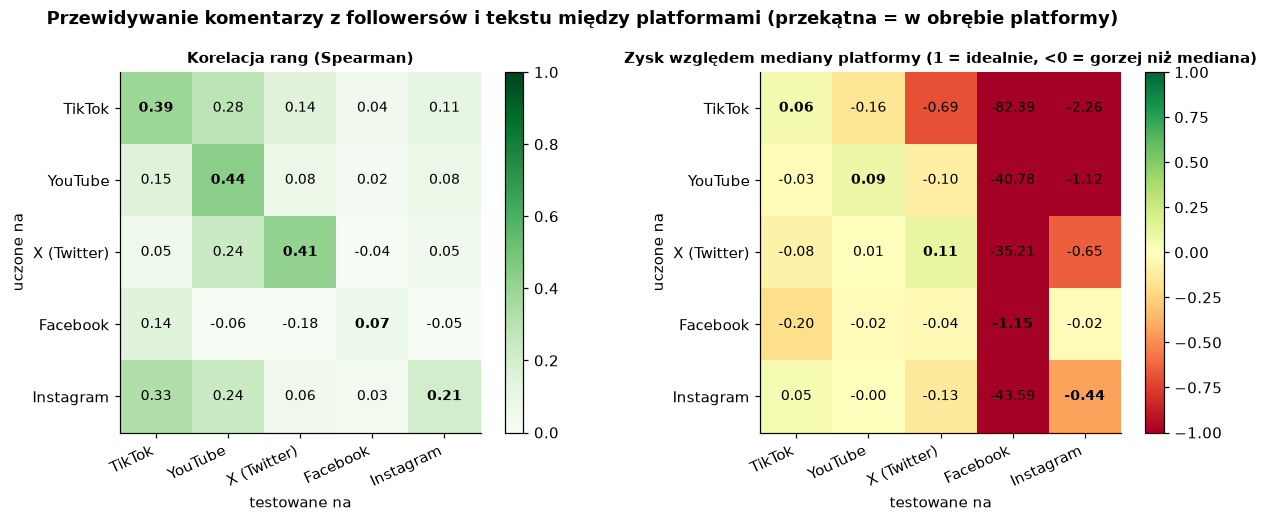

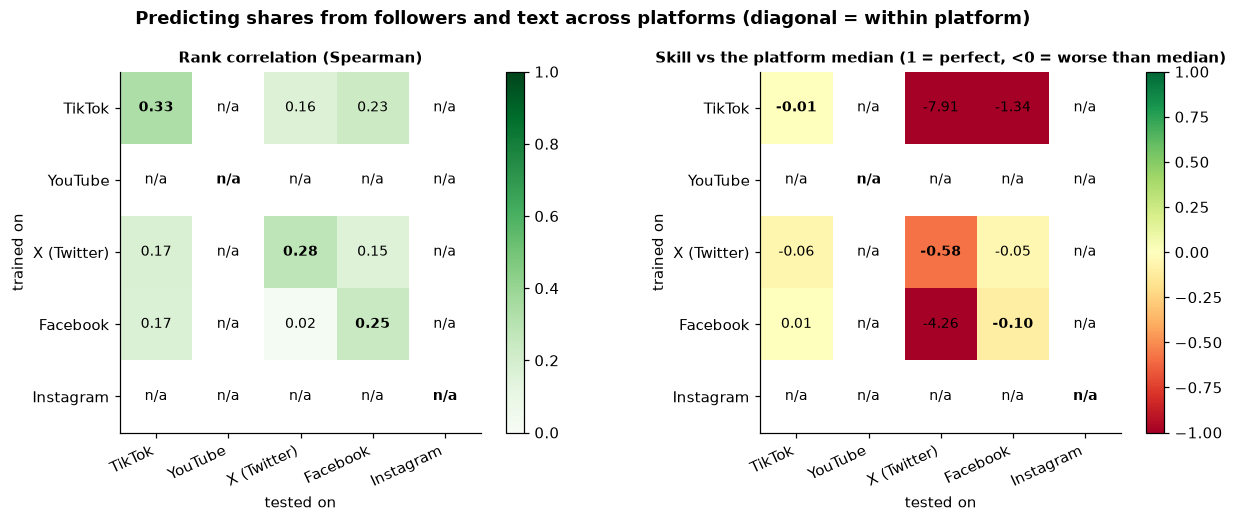

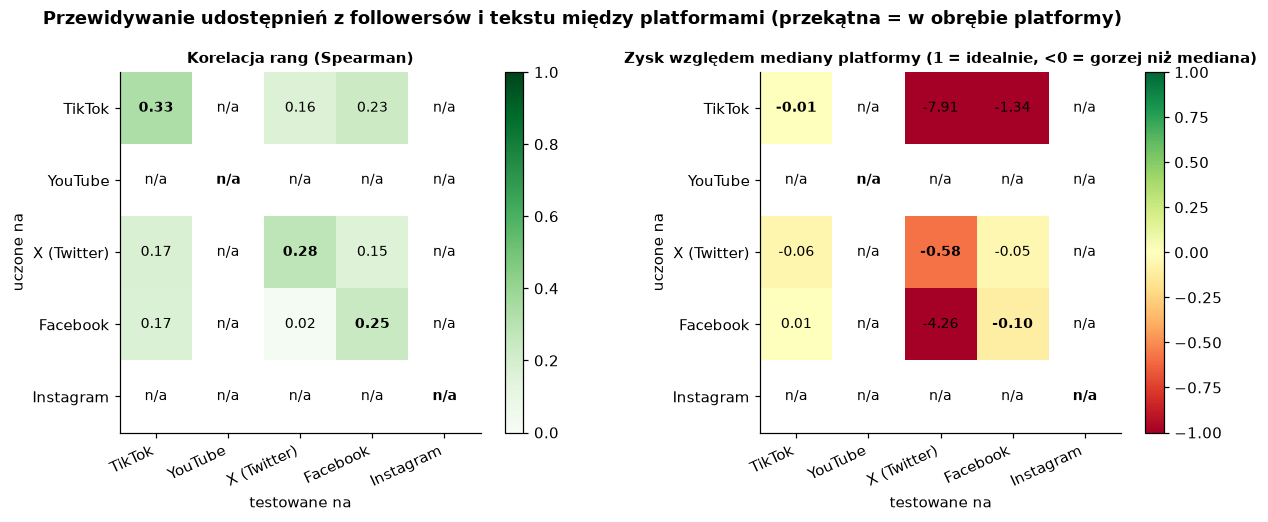

In [4]:
for t in res: xp.plot_matrix(res[t][1], res[t][2], t, ROOT / 'figures' / f'xplat_{t}_en.png', 'en'); xp.plot_matrix(res[t][1], res[t][2], t, ROOT / 'figures' / f'xplat_{t}_pl.png', 'pl')

Takeaway: followers and text alone predict engagement only weakly even inside a platform (rank correlation 0.3-0.47 for likes). The ordering partly transfers (for example TikTok to Facebook 0.33 against 0.41 on Facebook itself), but levels do not (negative skill): platforms differ in how many reactions a post of a given size gets. On Facebook and Instagram this link is not needed, because reactions are observed.

## Link 2 · reactions to views across platforms
The link that matters for Facebook and Instagram. Trained on two platforms, tested on the third. `bias` is the average level shift; `MAE after removing bias` is the error if we could calibrate the level, which we cannot on Facebook and Instagram. The own line shows slope and intercept of views against reactions on each platform.

In [5]:
xp.level_shift(tf.load(ROOT)).round(2)

,held-out platform,n,transfer MAE,bias (true - predicted),MAE after removing bias,own slope,own intercept
0,TikTok,2491,0.36,0.00,0.36,0.85,1.62
1,YouTube,2441,0.64,0.19,0.66,0.81,1.71
2,X (Twitter),1803,0.73,-0.48,0.61,1.25,1.18


Takeaway: slopes are similar (0.8 to 1.25), so the *shape* of the relation transfers, but intercepts differ by about 0.5 log10 (a factor of 3). That level is exactly what is unknown on Facebook and Instagram, so an estimate there carries an irreducible uncertainty of roughly a factor of 3 in level, on top of the within-platform error.